# Sequential fits

An in-situ experiment measures one specimen many times while something changes, such as temperature, time, pressure or gas.
rietx fits such a series pattern by pattern, and starts each fit from the answer before it.
We load a synthetic heating ramp from files, fit it and grade the result against the truth.
Then we break one pattern twice to see what the series reports.
By the end you can load and fit a series, read a parameter's trajectory, and check that the trajectory does not depend on the fitting order.

*Written by Claude Code, Anthropic's coding agent, for the rietx project.*

**You need** rietx 1.10 or later, which the next cell installs.
Notebook 02 introduces plans and a single refinement.

**The data** is made in the notebook: seven LaB₆ patterns on a synchrotron capillary instrument, each computed with [`predict`](https://rietx.org/docs/stable/reference/refinement.html#entry-points) and given Poisson noise.

**Runtime** is under 30 seconds on a laptop.

In [ ]:
%pip install rietx

## A synthetic heating ramp

Write LaB₆'s structure to a CIF and read it back.

In [1]:
import csv
import re
import tempfile
from pathlib import Path

import numpy as np

import rietx as rx

work = Path(tempfile.mkdtemp())
cif = work / "LaB6.cif"
cif.write_text(
    "data_LaB6\n_space_group_name_H-M_alt 'P m -3 m'\n"
    "_cell_length_a 4.1566\n_cell_length_b 4.1566\n_cell_length_c 4.1566\n"
    "_cell_angle_alpha 90\n_cell_angle_beta 90\n_cell_angle_gamma 90\n"
    "loop_\n_atom_site_label\n_atom_site_type_symbol\n_atom_site_fract_x\n"
    "_atom_site_fract_y\n_atom_site_fract_z\n_atom_site_B_iso_or_equiv\n"
    "La1 La 0 0 0 0.4\n"
    "B1  B  0.1996 0.5 0.5 0.4\n",
    encoding="utf-8",
)
lab6 = rx.Structure.from_cif(cif)

The ramp runs from 300 K to 900 K in steps of 100 K.
The lattice parameter a grows by 5 × 10⁻⁶ of its 300 K length per kelvin, which is 0.05 % a step.
`TRUE_A` holds the edge each pattern is made with.

In [2]:
TEMPERATURES = [300, 400, 500, 600, 700, 800, 900]
A0 = 4.1566  # Å, the lattice parameter a at 300 K
EXPANSION = 5e-6  # per K
TRUE_A = [A0 * (1 + EXPANSION * (t - 300)) for t in TEMPERATURES]

Next, the instrument every pattern is measured on, with a zero shift and a three-term background.

In [3]:
true_instrument = rx.Instrument.debye_scherrer(wavelength=0.4139)
true_instrument.zero_shift.value = 0.008
true_instrument.profile.w.value = 2.5e-4
true_instrument.background = rx.BackgroundChebyshev.with_terms(3)
true_instrument.background.coefficients[0].value = 40.0
true_instrument.background.coefficients[1].value = -6.0
true_instrument.background.coefficients[2].value = 1.5

`simulate` makes one pattern at a given lattice parameter a: `predict` computes it, and Poisson counts are drawn from it.
It stays a function because the ramp calls it once a pattern, and the last two sections call it again.

In [4]:
two_theta = np.arange(3.0, 24.0, 0.005)


def simulate(a, seed):
    specimen = lab6.model_copy(deep=True)
    for edge in "abc":
        getattr(specimen.phases[0].cell, edge).value = a
    specimen.phases[0].scale.value = 5e-4
    y = rx.Refinement(specimen, true_instrument).predict(two_theta)
    rng = np.random.default_rng(seed)
    counts = rng.poisson(np.maximum(y, 1.0)).astype(float)
    return rx.PatternData(two_theta=two_theta, intensity=counts)


patterns = [simulate(a, seed=11 + k) for k, a in enumerate(TRUE_A)]
patterns[0]

PatternData of 4200 points, 3–23.995° 2θ, median step 0.005°
  intensity:        <4200 floats 19…149332>
  sigma:            None
  excluded_regions: none
  metadata:         none

## Load a series from files

To rietx a series is an ordinary Python list of [`PatternData`](https://rietx.org/docs/stable/reference/data.html#pattern), in the order to fit them.
A real series arrives as a folder of files, so the work is putting them in that order with the right temperatures.
Write the synthetic patterns out as an instrument might: numbered by scan from 8, with the temperatures in a separate log.

In [5]:
folder = work / "ramp"
folder.mkdir()
for scan, pattern in enumerate(patterns, start=8):
    np.savetxt(
        folder / f"scan{scan}.xy",
        np.column_stack([pattern.two_theta, pattern.intensity]),
        fmt="%.4f %.0f",
        encoding="utf-8",
    )
log = "scan,temperature_K\n" + "".join(
    f"{scan},{t}\n" for scan, t in enumerate(TEMPERATURES, start=8)
)
(folder / "temperatures.csv").write_text(log, encoding="utf-8")

sorted(path.name for path in folder.glob("*.xy"))

['scan10.xy',
 'scan11.xy',
 'scan12.xy',
 'scan13.xy',
 'scan14.xy',
 'scan8.xy',
 'scan9.xy']

Sorted as text, `scan10` comes before `scan8`, because names compare character by character.
Sort on the number in the name instead, and look each temperature up in the log rather than assuming the order.

In [6]:
files = sorted(
    folder.glob("*.xy"),
    key=lambda path: int(re.search(r"\d+", path.stem).group()),
)
with open(folder / "temperatures.csv", encoding="utf-8", newline="") as handle:
    temperature_of = {
        f"scan{row['scan']}": float(row["temperature_K"])
        for row in csv.DictReader(handle)
    }

loaded = [rx.read_pattern(path) for path in files]
loaded_x = [temperature_of[path.stem] for path in files]
scans = [path.stem for path in files]
dict(zip(scans, loaded_x))

{'scan8': 300.0,
 'scan9': 400.0,
 'scan10': 500.0,
 'scan11': 600.0,
 'scan12': 700.0,
 'scan13': 800.0,
 'scan14': 900.0}

Print the names and their temperatures once like this before fitting.

Other naming conventions need only a different sort key.
When the temperature is in the file name, read it with a regular expression and sort on it.

In [7]:
names = ["LaB6_1000K.xye", "LaB6_300K.xye", "LaB6_650.5K.xye"]
sorted(names, key=lambda name: float(re.search(r"([\d.]+)K", name).group(1)))

['LaB6_300K.xye', 'LaB6_650.5K.xye', 'LaB6_1000K.xye']

One of rietx's readers takes each scan's temperature from the file header.
[Read the temperatures from your files](https://rietx.org/docs/stable/guides/series.html#read-the-temperatures-from-your-files) names it.

## The starting model

Start from what you would have before the first fit: the cell 0.1 % too large and no zero shift.
The width term W is 50 % too large, so the peaks start about 20 % too wide.

In [8]:
structure = lab6.model_copy(deep=True)
for edge in "abc":
    getattr(structure.phases[0].cell, edge).value = A0 * 1.001
instrument = rx.Instrument.debye_scherrer(wavelength=0.4139)
instrument.profile.w.value = 2.5e-4 * 1.5
instrument.background = rx.BackgroundChebyshev.with_terms(3)

[`refine_sequential`](https://rietx.org/docs/stable/reference/series.html#entry-points) works on copies of the two, so the same pair starts every series in this notebook.

## Fit the series

`refine_sequential` fits the patterns in list order, and starts each fit from the parameters the previous one finished with.
[`x`](https://rietx.org/docs/stable/reference/series.html#series-coordinate) places each pattern on the series axis, and `labels` names it.

[`carry`](https://rietx.org/docs/stable/reference/series.html#carried-parameters) says which parameters pass along the chain.
It is a list of [parameter-path globs](https://rietx.org/docs/stable/reference/parameter-table.html#names), as in a plan's stages.
A parameter that matches one starts each fit from the previous fit's value, and any other restarts from the starting model on every pattern.
`["*"]` carries everything and is the default, written out here.
`carry=["phases.*", "instrument.zero_shift"]` would restart the background and the peak widths on every pattern.
Each fit runs the [`mccusker_default`](https://rietx.org/docs/stable/reference/plans.html#mccusker-default) plan.

In [9]:
series = rx.refine_sequential(
    loaded,
    structure,
    instrument,
    carry=["*"],
    plan="mccusker_default",
    x=loaded_x,
    x_label="T (K)",
    labels=scans,
)
series

SeriesResult: 7 pattern(s), rietveld, direction=forward
  diagnostics: 2 rows, 0 errors; no deliverable given, so none is printed in full
    SEQUENTIAL_PERSISTENT_FINDING: warning under every purpose
    SEQUENTIAL_PERSISTENT_FINDING at instrument.geometry.goniometer_radius_mm: info
    pass deliverable= to summary() for the rows that decide your purpose; every row is in result.diagnostics
  trajectory (T (K)):
    largest step phases.0.cell.a 504.8σ at scan9→scan10 (series.steps)
    [1/7] scan8 x=300 converged Rwp=0.0409
    [2/7] scan9 x=400 converged Rwp=0.0409
    [3/7] scan10 x=500 converged Rwp=0.0399
    [4/7] scan11 x=600 converged Rwp=0.0405
    [5/7] scan12 x=700 converged Rwp=0.0406
    [6/7] scan13 x=800 converged Rwp=0.0402
    [7/7] scan14 x=900 converged Rwp=0.0404

Every pattern converged.
Both diagnostics are [`SEQUENTIAL_PERSISTENT_FINDING`](https://rietx.org/docs/stable/reference/diagnostics-series.html#sequential-persistent-finding), a per-pattern finding that fired on every pattern of the series.
Such a finding describes the model rather than any one fit.
[Read the diagnostics first](https://rietx.org/docs/stable/guides/series.html#read-the-diagnostics-first) explains these two.

Each entry records [which attempt](https://rietx.org/docs/stable/reference/series.html#restart-ladder) gave its values.

In [10]:
[entry.rung for entry in series]

['cold', 'warm', 'warm', 'warm', 'warm', 'warm', 'warm']

The first pattern ran the whole plan from the starting model.
Each later one started warm, from its neighbour's answer.
[Check where each fit started](https://rietx.org/docs/stable/guides/series.html#check-where-each-fit-started) describes the other attempts.

## The trajectory

[`series.trajectory`](https://rietx.org/docs/stable/reference/series.html#trajectories) returns one parameter across the series, with each point's esd.

In [11]:
a = series.trajectory("phases.0.cell.a")
a

Trajectory: phases.0.cell.a, 7 point(s)
  label   T (K)  value
  scan8   300    4.1565938(43)
  scan9   400    4.1586732(43)
  scan10  500    4.1607616(41)
  scan11  600    4.1628387(42)
  scan12  700    4.1649106(43)
  scan13  800    4.1669853(43)
  scan14  900    4.1690659(42)

Grade each point against the edge its pattern was made with, in esds.

In [12]:
x, value, esd = a.arrays()
np.round((value - TRUE_A) / esd, 1)

array([-1.5, -1.2,  1.2,  0.9, -0.6, -1.5, -0.9])

Every point lies within two esds of its true value.
The expansion is the slope of a weighted straight line through the points, divided by the edge at 300 K.
Print it beside the true value.

In [13]:
slope = np.polyfit(x, value, 1, w=1 / esd)[0]
print(slope / A0, EXPANSION)

4.9996785832738785e-06 5e-06


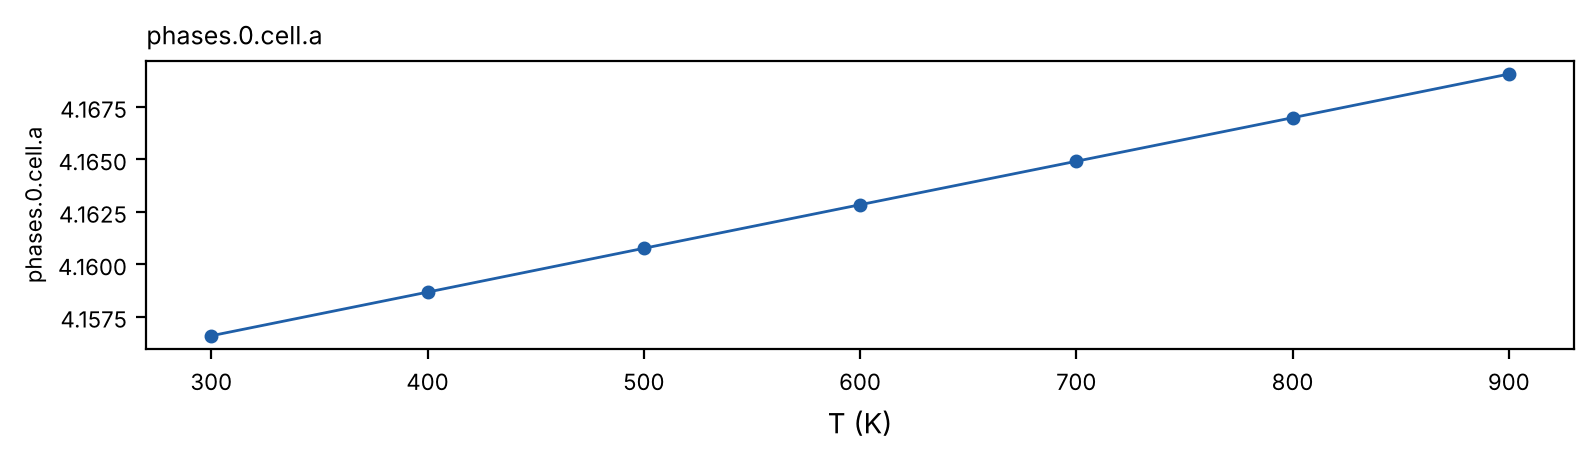

In [14]:
series.plot("phases.0.cell.a")

Each point carries its esd bar, too short to see at this scale.

## Check for path dependence

Each answer depends on the one before it.
An error in one fit can therefore travel down the chain and still draw a smooth curve.
[`direction="both"`](https://rietx.org/docs/stable/reference/series.html#forward-and-backward-chains) fits the chain from cold to hot and again from hot to cold, and compares the two.
A parameter they disagree on is flagged [`SEQUENTIAL_PATH_DEPENDENT`](https://rietx.org/docs/stable/reference/diagnostics-series.html#sequential-path-dependent).

[`summary(deliverable="series")`](https://rietx.org/docs/stable/reference/result.html#printing-a-result) prints the rows that decide whether a trajectory can be quoted.

In [15]:
both = rx.refine_sequential(
    loaded,
    structure,
    instrument,
    plan="mccusker_default",
    x=loaded_x,
    x_label="T (K)",
    labels=scans,
    direction="both",
)
print(both.summary(deliverable="series"))

SeriesResult: 7 pattern(s), rietveld, direction=both
  diagnostics under series: 1 warning, 0 errors, 1 info
    warning[SEQUENTIAL_PERSISTENT_FINDING]: PATTERN_UNDERSAMPLED fired on the fit in 7 of 7 patterns (100% of the series).
      help: Change the model or the plan.
    info: SEQUENTIAL_PERSISTENT_FINDING at instrument.geometry.goniometer_radius_mm
  trajectory (T (K)):
    largest step phases.0.cell.a 504.8σ at scan9→scan10 (series.steps)
    [1/7] scan8 x=300 converged Rwp=0.0409
    [2/7] scan9 x=400 converged Rwp=0.0409
    [3/7] scan10 x=500 converged Rwp=0.0399
    [4/7] scan11 x=600 converged Rwp=0.0405
    [5/7] scan12 x=700 converged Rwp=0.0406
    [6/7] scan13 x=800 converged Rwp=0.0402
    [7/7] scan14 x=900 converged Rwp=0.0404
  deliverable: series (a parameter against the series axis)
    ordering artefact: measured both ways, 0 parameter(s) disagree (none)
    persistent findings: 2
      CAPILLARY_OFFSET_UNAVAILABLE fired on instrument.geometry.goniometer_radius_

The `ordering artefact` row says the comparison ran and no parameter disagreed.
The `2θ-scale anchor` row and the two after it are yours to answer.
Nothing in a pattern file says what pins the 2θ scale.

`both.backward` holds the hot-to-cold chain.
Its trajectory matches the one above.

In [16]:
both.backward.trajectory("phases.0.cell.a")

Trajectory: phases.0.cell.a, 7 point(s)
  label   T (K)  value
  scan8   300    4.1565938(43)
  scan9   400    4.1586732(43)
  scan10  500    4.1607616(41)
  scan11  600    4.1628387(42)
  scan12  700    4.1649106(43)
  scan13  800    4.1669853(43)
  scan14  900    4.1690659(42)

[How to check a series for path dependence](https://rietx.org/docs/stable/guides/path.html) explains how to read a disagreement.

## A jump in the series

Give the 700 K pattern a cell 2 % larger than its neighbours', as a phase transition might.

In [17]:
jumped = list(loaded)
jumped[4] = simulate(TRUE_A[4] * 1.02, seed=15)
series_jump = rx.refine_sequential(
    jumped,
    structure,
    instrument,
    plan="mccusker_default",
    x=loaded_x,
    x_label="T (K)",
    labels=scans,
)
series_jump

SeriesResult: 7 pattern(s), rietveld, direction=forward
  diagnostics: 2 rows, 0 errors; no deliverable given, so none is printed in full
    SEQUENTIAL_PERSISTENT_FINDING: warning under every purpose
    SEQUENTIAL_PERSISTENT_FINDING at instrument.geometry.goniometer_radius_mm: info
    pass deliverable= to summary() for the rows that decide your purpose; every row is in result.diagnostics
  trajectory (T (K)):
    largest step phases.0.cell.a 21070.2σ at scan11→scan12 (series.steps)
    [1/7] scan8 x=300 converged Rwp=0.0409
    [2/7] scan9 x=400 converged Rwp=0.0409
    [3/7] scan10 x=500 converged Rwp=0.0399
    [4/7] scan11 x=600 converged Rwp=0.0405
    [5/7] scan12 x=700 converged Rwp=0.0390
    [6/7] scan13 x=800 converged Rwp=0.0402
    [7/7] scan14 x=900 converged Rwp=0.0404

The trajectory block names the largest step in [`series_jump.steps`](https://rietx.org/docs/stable/reference/series.html#steps-between-patterns).
That list holds every parameter's step between neighbouring patterns, in esds of the later fit, largest first.
The cubic cell ties b and c to a, so the three step together.

In [18]:
series_jump.steps[:3]

[SeriesStep
  path:     'phases.0.cell.a'
  labels:   ['scan11', 'scan12']
  indices:  [3, 4]
  step:     0.085369877
  size_esd: 21070.214,
 SeriesStep
  path:     'phases.0.cell.b'
  labels:   ['scan11', 'scan12']
  indices:  [3, 4]
  step:     0.085369877
  size_esd: 21070.214,
 SeriesStep
  path:     'phases.0.cell.c'
  labels:   ['scan11', 'scan12']
  indices:  [3, 4]
  step:     0.085369877
  size_esd: 21070.214]

rietx calls no step a jump.
A large one may be a phase transition, a sample shift, a beam dump or a failed fit, and only the sample's history can say which, so check the pattern's own fit before reading it as physics.
[Check a step against two independent fits](https://rietx.org/docs/stable/guides/path.html#check-a-step-against-two-independent-fits) shows the check rietx runs for you, `verify_steps=k`.

Here the 700 K fit found the larger cell.

In [19]:
series_jump.trajectory("phases.0.cell.a")

Trajectory: phases.0.cell.a, 7 point(s)
  label   T (K)  value
  scan8   300    4.1565938(43)
  scan9   400    4.1586732(43)
  scan10  500    4.1607616(41)
  scan11  600    4.1628387(42)
  scan12  700    4.2482085(41)
  scan13  800    4.1669853(43)
  scan14  900    4.1690659(42)

Now read which attempt gave each pattern its values.

In [20]:
[entry.rung for entry in series_jump]

['cold', 'warm', 'warm', 'warm', 'warm', 'warm', 'warm']

Every pattern after the first took its values from the plain [`warm`](https://rietx.org/docs/stable/reference/series.html#restart-ladder) attempt, the 700 K one included.
Started from the 600 K answer, that fit reached the cell 2 % larger on its own.
When a warm start fails, the series fits the pattern again with the whole plan from the same start.
That attempt is `warm_staged`, and this list is where it would show.

## A pattern the chain cannot fit

Make the jump 5 %, beyond what any starting point here can reach.

In [21]:
broken = list(loaded)
broken[4] = simulate(TRUE_A[4] * 1.05, seed=15)
series_broken = rx.refine_sequential(
    broken,
    structure,
    instrument,
    plan="mccusker_default",
    x=loaded_x,
    x_label="T (K)",
    labels=scans,
)
series_broken

SeriesResult: 7 pattern(s), rietveld, direction=forward
  diagnostics: 4 rows, 0 errors; no deliverable given, so none is printed in full
    SEQUENTIAL_RESEED at scan12: warning under every purpose
    SEQUENTIAL_RWP_OUTLIER at scan12: warning under every purpose
    SEQUENTIAL_PERSISTENT_FINDING: warning under every purpose
    SEQUENTIAL_PERSISTENT_FINDING at instrument.geometry.goniometer_radius_mm: info
    pass deliverable= to summary() for the rows that decide your purpose; every row is in result.diagnostics
  trajectory (T (K)):
    largest step phases.0.cell.a 504.8σ at scan9→scan10 (series.steps)
    [1/7] scan8 x=300 converged Rwp=0.0409
    [2/7] scan9 x=400 converged Rwp=0.0409
    [3/7] scan10 x=500 converged Rwp=0.0399
    [4/7] scan11 x=600 converged Rwp=0.0405
    [5/7] scan12 x=700 converged Rwp=0.9687
    [6/7] scan13 x=800 converged Rwp=0.0402
    [7/7] scan14 x=900 converged Rwp=0.0404

[`SEQUENTIAL_RWP_OUTLIER`](https://rietx.org/docs/stable/reference/diagnostics-series.html#sequential-rwp-outlier) names the 700 K pattern.
The row's message is in `series_broken.diagnostics`.
It says every attempt left its Rwp far above the fence, the limit the series sets from the patterns accepted before it.
The series kept the best attempt and moved on.
Read that pattern's own diagnostics.

In [22]:
series_broken[4].diagnostics

[warning[FLOOR_HIT]: phases.0.scale refined to its floor (ρ=+0.001).
  at: phases.0.scale
  help: Quote an upper limit instead of a value, or remove the parameter if its phase or term is unsupported. For a displacement parameter, check absorption, species and occupancy.,
 info[CAPILLARY_OFFSET_UNAVAILABLE]: This capillary geometry declares no goniometer radius, so the eq (4) specimen-offset aberrations are held at zero.
  at: instrument.geometry.goniometer_radius_mm
  help: Set instrument.geometry.goniometer_radius_mm if you know the diffractometer's.,
 warning[PHASE_UNCONSTRAINED]: Phase 0 (LaB6)'s scale was at most 0σ from zero against the counting noise at the last stage's answer, under the 3σ a phase needs to count as seen. Its 1 structural parameter was held for stages cell, profile_w, profile, closing.
  at: phases.0.cell.a
  help: Treat those values as unmeasured. Take the phase out of the model, or seed its scale off the floor before you free anything else of it.,
 error[MODEL_

The best attempt put the LaB₆ scale on its floor of zero ([`FLOOR_HIT`](https://rietx.org/docs/stable/reference/diagnostics-refinement.html#floor-hit)).
[`MODEL_FAR_FROM_DATA`](https://rietx.org/docs/stable/reference/diagnostics-refinement.html#model-far-from-data) says not to read any of this pattern's values.
[`PHASE_UNCONSTRAINED`](https://rietx.org/docs/stable/reference/diagnostics-refinement.html#phase-unconstrained) says the cell was held, because a phase with no scale does not constrain it.
A held value is not a measurement, so the trajectory has no 700 K point.

In [23]:
series_broken.trajectory("phases.0.cell.a")

Trajectory: phases.0.cell.a, 6 point(s)
  label   T (K)  value
  scan8   300    4.1565938(43)
  scan9   400    4.1586732(43)
  scan10  500    4.1607616(41)
  scan11  600    4.1628387(42)
  scan13  800    4.1669853(43)
  scan14  900    4.1690659(42)

The other six points match the clean series to every printed digit.

A fit that diverges on every attempt goes one step further.
[`SEQUENTIAL_UNRECOVERED`](https://rietx.org/docs/stable/reference/diagnostics-series.html#sequential-unrecovered) names it, and the pattern is [quarantined](https://rietx.org/docs/stable/reference/series.html#quarantine): it seeds no successor, and its Rwp stays out of the median that sets the fence.
The 700 K fit here converged, so it still seeded the 800 K fit.

A hold or a tie belongs to one refinement, so a series declares it per pattern.
[Keep a parameter fixed or tied on every pattern](https://rietx.org/docs/stable/guides/series.html#keep-a-parameter-fixed-or-tied-on-every-pattern) shows how.